In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. DC CIRCUIT SIMULATION
# Voltage Divider Circuit

In [2]:
Vs = 12                 # DC supply voltage
R1 = 1000               # Resistance R1 in ohms
R2 = 2000               # Resistance R2 in ohms

# Calculate simulated output voltage
Vout_dc = Vs * R2 / (R1 + R2)

# Illustrative breadboard measurement
measured_dc = 7.92

# Calculate percentage error
error_dc = abs(Vout_dc - measured_dc) / Vout_dc * 100

print("DC CIRCUIT ANALYSIS")
print("-------------------------")
print("Supply Voltage:", Vs, "V")
print("Simulated Output Voltage:", round(Vout_dc, 2), "V")
print("Illustrative Measured Voltage:", measured_dc, "V")
print("Percentage Error:", round(error_dc, 2), "%")

DC CIRCUIT ANALYSIS
-------------------------
Supply Voltage: 12 V
Simulated Output Voltage: 8.0 V
Illustrative Measured Voltage: 7.92 V
Percentage Error: 1.0 %


# 2. AC CIRCUIT SIMULATION
# Series RC Circuit
# Output voltage across capacitor

In [3]:
Vrms = 12
R = 1000
C = 1e-6
frequency = 50

omega = 2 * np.pi * frequency

# Capacitive reactance
Xc = 1 / (omega * C)

# Calculate capacitor voltage (RMS)
Vc_rms = Vrms * Xc / np.sqrt(R**2 + Xc**2)

# Phase angle
phase_angle = -np.arctan(omega * R * C)

# Illustrative breadboard measurement
measured_ac = 11.30

# Calculate percentage error
error_ac = abs(Vc_rms - measured_ac) / Vc_rms * 100

print("\nAC CIRCUIT ANALYSIS")
print("-------------------------")
print("Supply Voltage:", Vrms, "V RMS")
print("Frequency:", frequency, "Hz")
print("Capacitive Reactance:", round(Xc, 2), "Ohms")
print("Simulated Capacitor Voltage:", round(Vc_rms, 2), "V RMS")
print("Illustrative Measured Voltage:", measured_ac, "V RMS")
print("Percentage Error:", round(error_ac, 2), "%")


AC CIRCUIT ANALYSIS
-------------------------
Supply Voltage: 12 V RMS
Frequency: 50 Hz
Capacitive Reactance: 3183.1 Ohms
Simulated Capacitor Voltage: 11.45 V RMS
Illustrative Measured Voltage: 11.3 V RMS
Percentage Error: 1.3 %


# 3. AC WAVEFORM GENERATION

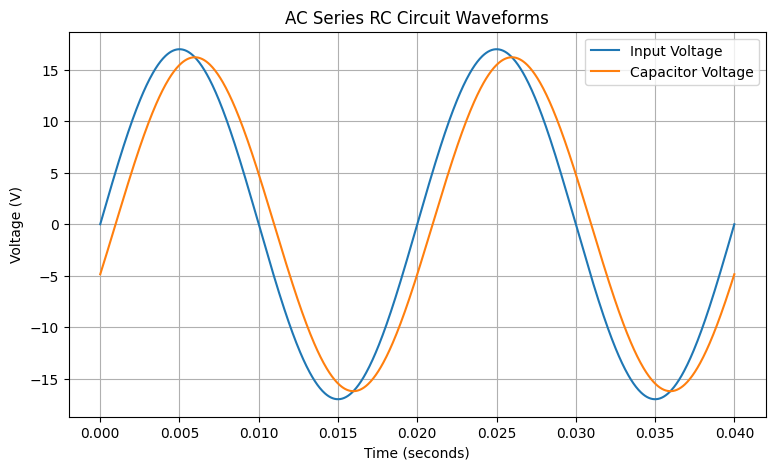

In [4]:
time = np.linspace(0, 0.04, 1000)

Vs_peak = Vrms * np.sqrt(2)
Vc_peak = Vc_rms * np.sqrt(2)

# Input voltage waveform
input_wave = Vs_peak * np.sin(omega * time)

# Capacitor voltage waveform
output_wave = Vc_peak * np.sin(
    omega * time + phase_angle
)

plt.figure(figsize=(9, 5))

plt.plot(time, input_wave, label="Input Voltage")
plt.plot(time, output_wave, label="Capacitor Voltage")

plt.xlabel("Time (seconds)")
plt.ylabel("Voltage (V)")
plt.title("AC Series RC Circuit Waveforms")
plt.grid(True)
plt.legend()
plt.show()

# 4. VOLTAGE COMPARISON

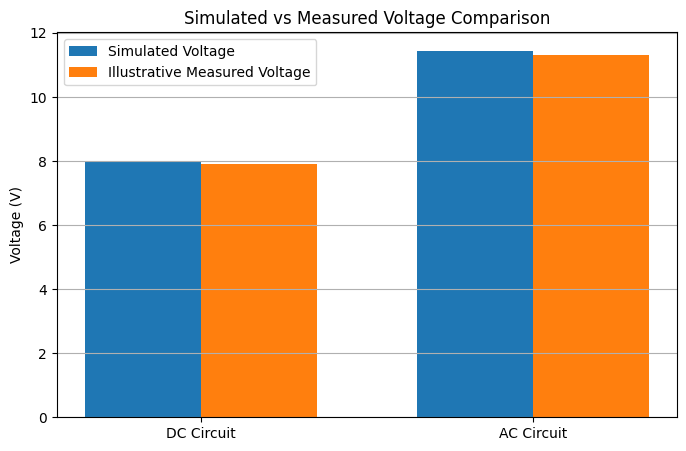

In [5]:
circuit_names = ["DC Circuit", "AC Circuit"]

simulated = [Vout_dc, Vc_rms]
measured = [measured_dc, measured_ac]

x = np.arange(len(circuit_names))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, simulated, width,
        label="Simulated Voltage")

plt.bar(x + width/2, measured, width,
        label="Illustrative Measured Voltage")

plt.xticks(x, circuit_names)
plt.ylabel("Voltage (V)")
plt.title("Simulated vs Measured Voltage Comparison")
plt.legend()
plt.grid(axis="y")
plt.show()